# Attention-based Neurosymbolic Differentiable Rule Extractor (ANDRE)

**Creator**: Iman Sharifi, G46454668

### Learning the rules for Even/Odd numbers from a generic dataset

In [15]:
import numpy as np
import torch
import torch.nn.functional as F

def interpret_neuron_weights_entropy_(body_preds, pred_values, Weights, entropy_threshold=1):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        body_preds (list): A list of predicate strings for each neuron, like ['b1', 'b2', ...] or ['b1(X1, X2)', 'b2(X3)', ...]
        pred_value: The predicted value to be used in interpretation. it is a scalar value between 0 and 1.
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    
    interpretations = []
    for i, weights in enumerate(Weights):
        weights_tensor = torch.tensor(weights, dtype=torch.float32)
        entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
        # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

        if entropy > entropy_threshold:
            interpretations.append('1')
            continue

        # Find predicate value of a given neuron
        pred_value = pred_values[i]
        body_pred = body_preds[i]

        # compute {pred_value*weights[0], (1-pred_value)*weights[1], weights[2]}
        new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]

        max_index = np.argmax(new_weights)
        if max_index == 0:
            interpretations.append(f'{body_pred}')
            continue
        elif max_index == 1:
            interpretations.append(f'not({body_pred})')
            continue
        else:
            interpretations.append('1')

    return interpretations

def interpret_neuron_weights_entropy(pred_values, Weights, entropy_threshold=0.8):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1',
    only if entropy is below a threshold to ensure confidence in prediction.

    Args:
        pred_values (numpy.ndarray): A 1D array with predicate values (between 0 and 1).
        Weights (list of list): A 2D list where each row is the softmaxed weights of a neuron.
        entropy_threshold (float): The threshold of entropy above which output is considered uncertain.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron, or '?' for uncertain.
    """
    interpretations = []
    for i, weights in enumerate(Weights):
        weights_tensor = torch.tensor(weights, dtype=torch.float32)
        entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
        # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

        if entropy > entropy_threshold:
            interpretations.append('1')
            continue

        pred_value = pred_values[i]
        new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]
        max_index = np.argmax(new_weights)

        if max_index == 0:
            interpretations.append(f'b{i+1}')
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
        else:
            interpretations.append('1')

    return interpretations

In [16]:
def compute_acc_ratio(model, x, y, rule_idx):
    with torch.no_grad():
        rule = model.rules[rule_idx]
        body_conj = sum(rule[i](x[:, [i]]) for i in range(model.num_neurons_per_rule))
        rule_weights = []
        for neuron in rule:
            weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
            rule_weights.append(weights)

        num_body_preds = x.shape[1] - sum([1 for w in rule_weights if np.round(w[2]) == 1.0])
        threshold = 0.5**(num_body_preds)
        body = (torch.exp(body_conj) >= threshold).float()

        # Match the shape of body with y
        if body.shape != y.shape:
            body = body.squeeze(-1)

        # find cosine similarity between body and y
        cos_sim = nn.CosineSimilarity(dim=0)(body, y)

        return cos_sim.item()

def compute_acc_ratio_all_rules(model, x, y):
    with torch.no_grad():
        for rule_idx, rule in enumerate(model.rules):
            pred_values = [rule[i](x[:, [i]]) for i in range(model.num_neurons_per_rule)]
            rule_weights = []
            for neuron in rule:
                weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
                rule_weights.append(weights)

            # This should be double checked because it may not be accurate
            num_body_preds = x.shape[1] - sum([1 for w in rule_weights if np.argmax(w) == 2 and np.round(w[2]) == 1.0]) # x.shape[1] is the number of potential body predicates
            threshold = 0.5**(num_body_preds)
            body = (torch.exp(body_conj) >= threshold).float()

            if rule_idx == 0:
                fuzzy_or = body
            else:
                fuzzy_or = fuzzy_or + body - fuzzy_or * body

        # Match the shape of body with y
        if fuzzy_or.shape != y.shape:
            fuzzy_or = fuzzy_or.squeeze(-1)

        # find cosine similarity between body and y
        cos_sim = nn.CosineSimilarity(dim=0)(fuzzy_or, y)

        return cos_sim.item()

def compute_acc_ratio_all_rules_attention(model, x, y, beta=10.0):
    with torch.no_grad():
        rule_outputs = []
        for rule in model.rules:
            conjunctions = []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % model.input_dim]]
                conjunctions.append(neuron(xi).squeeze())
            # Softmin attention over neurons (optional, or just use sum)
            conjunctions = torch.stack(conjunctions, dim=1)  # (batch, num_neurons)
            attention_weights = torch.softmax(-beta * conjunctions, dim=1)
            outputs = (attention_weights * conjunctions).sum(dim=1)  # (batch,)
            activated_outputs = torch.sigmoid(5 * (outputs - 0.5))
            rule_outputs.append(activated_outputs)

        # Stack rule outputs: shape (num_rules, batch)
        rule_outputs_tensor = torch.stack(rule_outputs, dim=0)  # (num_rules, batch)
        # Softmax attention over rules for each sample (dim=0)
        attention_weights = torch.softmax(beta * rule_outputs_tensor, dim=0)
        # Weighted sum over rules for each sample
        final_output = (attention_weights * rule_outputs_tensor).sum(dim=0)  # (batch,)
        # Compute accuracy
        preds = (final_output > 0.5).float()
        acc = (preds == (y > 0.5)).float().mean().item()
        return acc

# compute_acc_ratio(best_model, X_train, y_train, 0)

## Learning Structured Rules

Given this set of potential predicates $\{b_1(X_1, X_2), b_2(X_1), b_3(X_2, X_3), b_4(X_1, X_3)\}$ and the binary values for the head predicate $h(X_1, X_3)$, we aim to find the following target rule:

$h(X_1, X_3) :- b_1(X_1, X_2) \wedge \neg b_3(X_2, X_3)$,

where head variables are $X_1$ and $X_3$, and $X_2$ is an auxiliary variable. Each rule should satisfy these two conditions:

- Head variables should be present in the body of the rule.

- Auxiliary variables either should not be available in the body of the rule or should be available at least twice.

To enforce such conditions, we consider the following vector embeddings:

$X = [X_m]_{j=1}^m$, where $x_j$ is the probability of the existense of variable $X_j$ in the body predicates. The desired body variable embedding vector for the aforementioned target rule is $X_d = [X_1 = 1 , X_2 = 2, X_3 = 1, ..., X_m = 0]$

To find the variable embeddings for each rule, we firstly find the probablity of existense of a given predicate in the rule using its associated trainable weights. We know that each predicate $B_i$ has three weights $w_i^1$, $w_i^2$, and $w_i^3$ corresponding to $b_i$, $\neg b_i$, and $1$. Given this, we know that $w_i^3$ shows the probability of $B_i$ not being in the body of the rule. Therefore, $1-w_i^3$ is the probability of a given predicate appearing in the body of the rule at each training step, meaning $P = [1-w_i^3]_{i=1}^n$.

In the next step, we find the vector embeddings showing the existense of a given predicate in each potential predicate. Assume we have such potential predicates $\{B_i\}_{i=1}^n$ and variables $\{X_j\}_{j=1}^m$. If we assume that $v_{ij}$ is the probability of existense of variable $X_j$ in $B_i$, $v_{ij}$ is either 0 or 1, meaning $v_{ij} \in \{0, 1\}$. $V = [v_{ij}]_{n \times m}$ is a binary matrix describing the existense of a given variable in a given predicate.

Then the final probability vector is extracted using the following equation:
$M = P.V = [M_j]_{j=1}^m$


## Additional Loss Functions

1- Range Restricted Loss Function

$P_R = \prod_{i \in V_h} M[X_i]$

$L_R = MEAN(SIGMOID(-10(P_R-0.5))$

2- Connected Loss Function

$L_C = MEAN(0.5*N(MU=1, STD=0.2))$



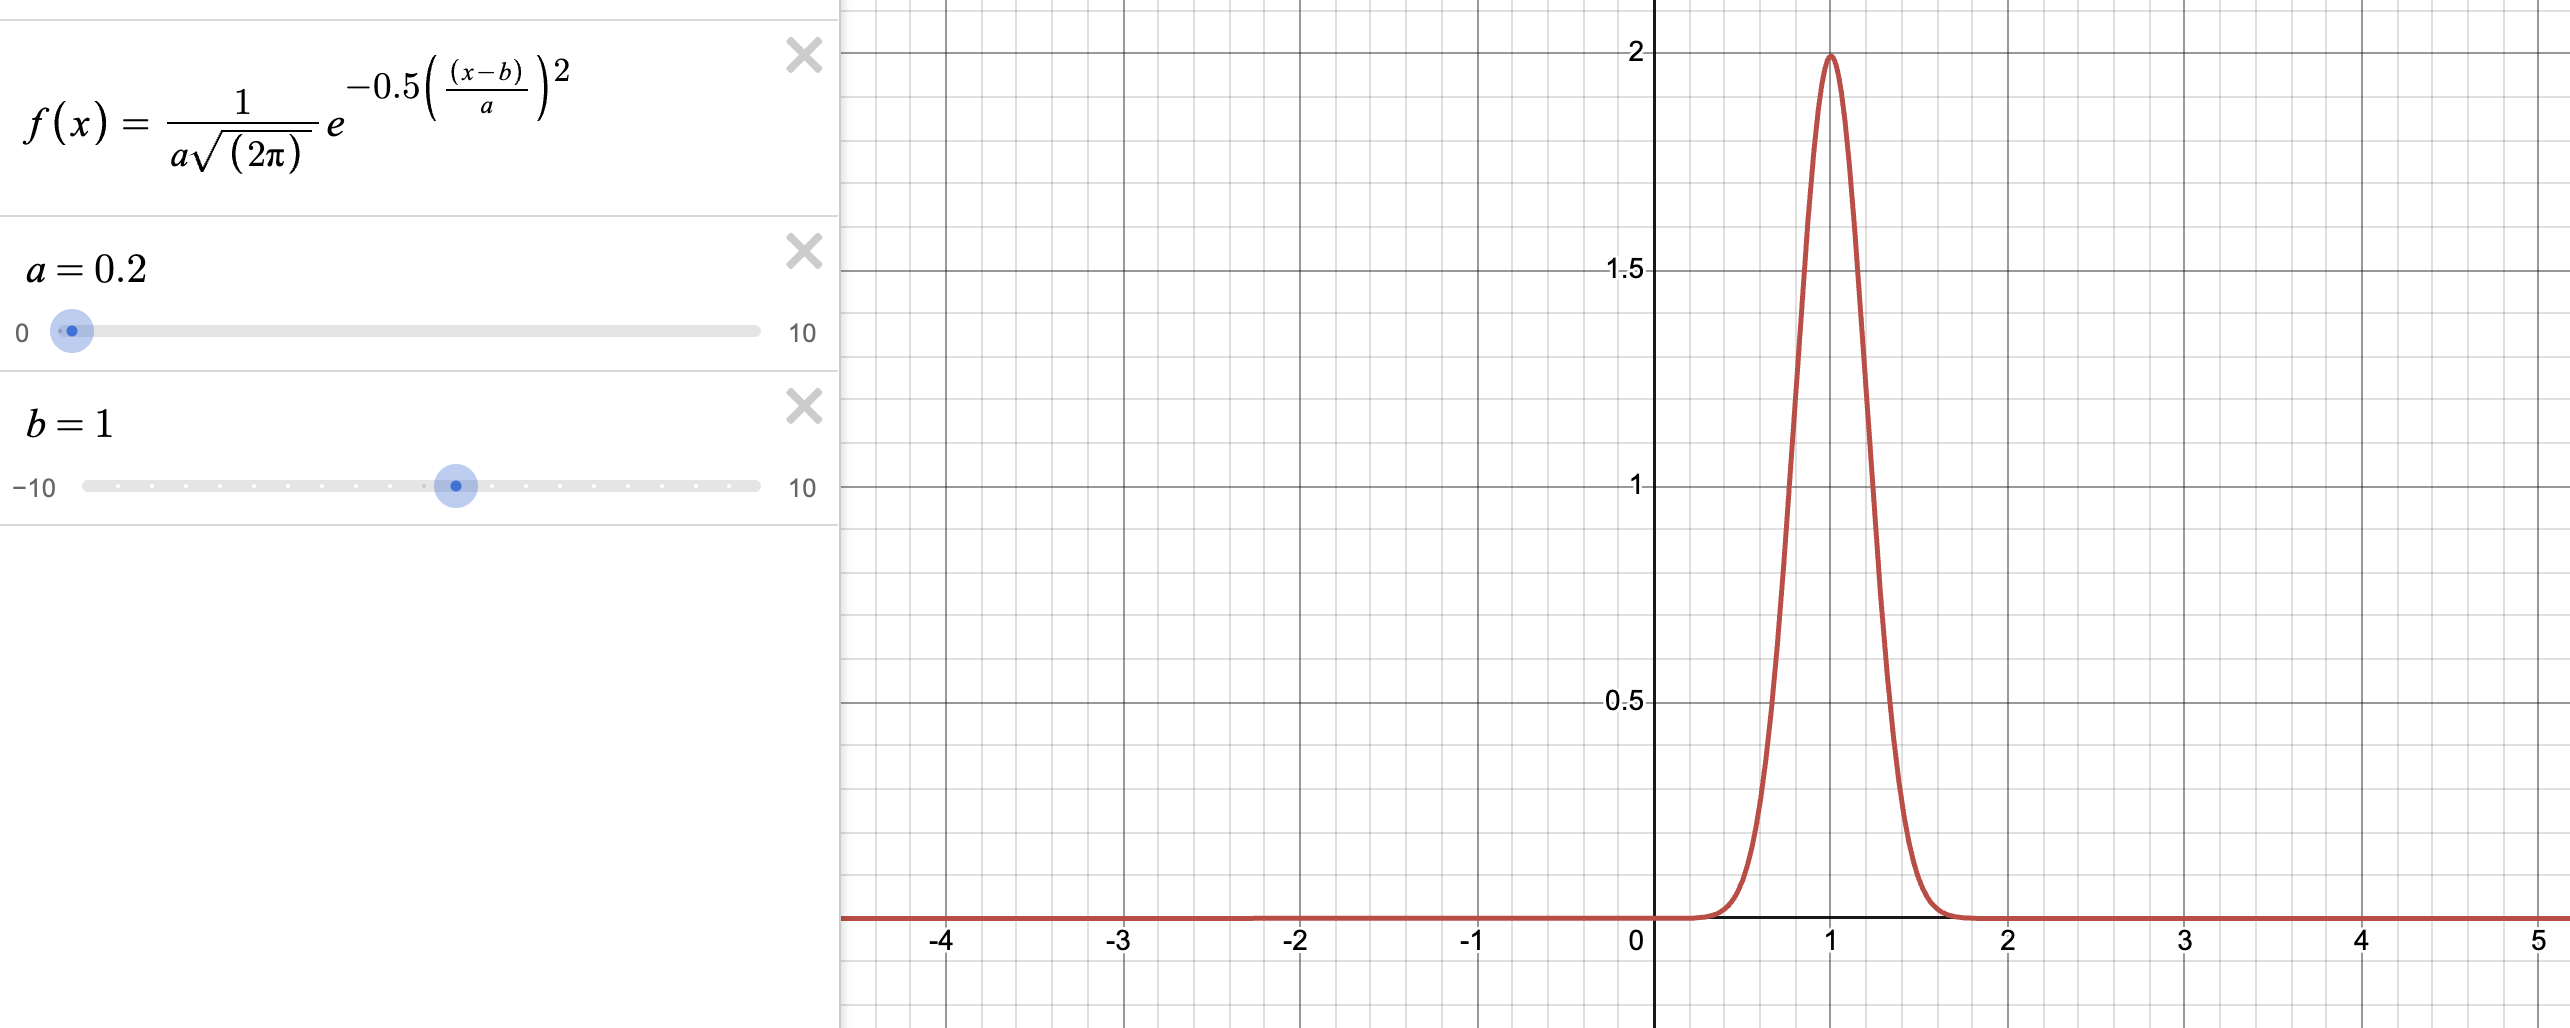

In [19]:
import torch
import re

def create_V_matrix(predicates):
    # Extract all variable names
    variable_set = set()
    predicate_vars = []
    for pred in predicates:
        # Extract variables inside parentheses
        vars_in_pred = re.findall(r'\((.*?)\)', pred)
        if vars_in_pred:
            vars_list = [v.strip() for v in vars_in_pred[0].split(',')]
        else:
            vars_list = []
        predicate_vars.append(vars_list)
        variable_set.update(vars_list)
    # Sort variables for consistent column order
    variables = sorted(variable_set, key=lambda x: (int(x[1:]) if x[1:].isdigit() else x))
    var_idx = {v: i for i, v in enumerate(variables)}
    # Build the matrix
    V = torch.zeros((len(predicates), len(variables)), dtype=torch.float32)
    for i, vars_list in enumerate(predicate_vars):
        for v in vars_list:
            V[i, var_idx[v]] = 1.0
    return V, variables

## Network

In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 20.0  # Example value for beta
LAMBDA = 10.0  # Example value for lambda

# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(0.2*self.raw_weights, dim=0)
        # self.weights = torch.sigmoid(self.raw_weights)  # Use sigmoid to ensure weights are in [0, 1]
        # self.weights = self.weights / self.weights.sum()  # Normalize weights to sum to 1
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input

# Define FuzzyDisjunctionNet
class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim, variable_matrix):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.V = variable_matrix
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        self.M_matrices = []
        rule_outputs = []

        for i, rule in enumerate(self.rules):
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            P = []
            for j, neuron in enumerate(rule):
                xi = x[:, [j % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
                P.append(1.0 - weights[2])  # 1 - w3

            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)

            P_tensor = torch.stack(P)
            M = torch.matmul(P_tensor, self.V)
            self.M_matrices.append(M)

            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            activated_outputs = torch.sigmoid(LAMBDA*(sum(outputs) - 0.5))  # Apply sigmoid to the sum
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        activated_output = torch.sigmoid(LAMBDA*(sum(rule_outputs) - 0.5))  # Apply sigmoid to the sum

        return activated_output

## Curriculum Learning


Learning Rule #1
Num Rules: 1, Restart 1/1, Final Loss: 0.5796.
Restart 1: acc_ratio = 0.6100
Best acc_ratio for Rule 1: 0.6100

Learning Rule #2
Num Rules: 2, Restart 1/1, Final Loss: 0.4849.
Restart 1: acc_ratio = 0.6722
Best acc_ratio for Rule 2: 0.6722

Learning Rule #3
Num Rules: 3, Restart 1/1, Final Loss: 0.4830.
Restart 1: acc_ratio = 0.7045
Best acc_ratio for Rule 3: 0.7045

Learning Rule #4
Num Rules: 4, Restart 1/1, Final Loss: 0.5349.
Restart 1: acc_ratio = 0.7153
Best acc_ratio for Rule 4: 0.7153


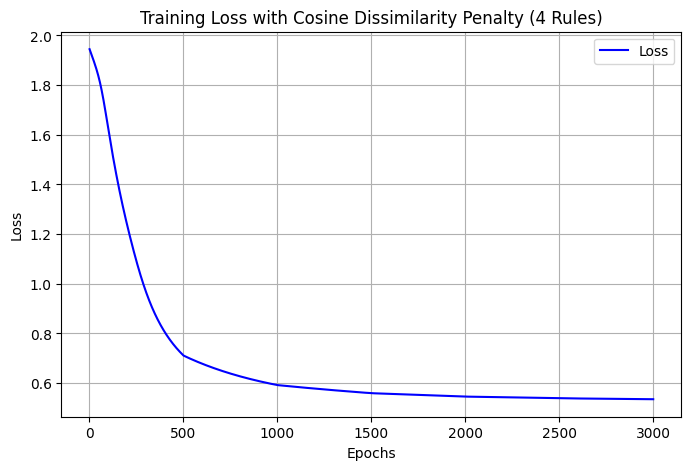


Final M matrices:
M1: [1. 2. 1.]
M2: [1. 2. 1.]
M3: [1. 2. 1.]
M4: [1. 2. 1.]
The most repeated rule is: 'h1 :- father(X2, X3) and mother(X1, X2).'
Accuracy over training data: 1.0.
The most repeated rule is: 'h2 :- father(X1, X2) and mother(X2, X3).'
Accuracy over training data: 1.0.
The most repeated rule is: 'h3 :- mother(X1, X2) and mother(X2, X3).'
Accuracy over training data: 1.0.
The most repeated rule is: 'h4 :- father(X1, X2) and mother(X2, X3).'
Accuracy over training data: 1.0.

Final Rule:
target(X1, X3) :- father(X2, X3) and mother(X1, X2) OR father(X1, X2) and mother(X2, X3) OR mother(X1, X2) and mother(X2, X3) OR father(X1, X2) and mother(X2, X3).


In [26]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import math
from collections import Counter

# Target body predicates and their variables
# We assume the model doesn't know the variables of the predicates beforehand, so we want to learn them
predicates = ["father(X1, X2)", "father(X2, X3)", "father(X1, X3)", "mother(X1, X2)", "mother(X2, X3)", "mother(X1, X3)"]

# Define predicate-variable binary matrix 
# Here the variables are known for each predicate
# update variable_matrix to match the predicates ["father(X1, X2)", "father(X2, X3)", "father(X1, X3)", 
# "mother(X1, X2)", "mother(X2, X3)", "mother(X1, X3)""]

variable_matrix, variables = create_V_matrix(predicates)

# Set random seed for reproducibility
torch.manual_seed(42)
input_dim = 6  # Number of features in X_train
num_neurons_per_rule = input_dim  # Number of neurons per rule
num_samples = 4000  # For testing, we can use a smaller number of samples

# X_train = (torch.rand(num_samples, input_dim) > 0.5).float()  # Random binary features
X_train = torch.rand(num_samples, input_dim)
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
           ((X_train[:, 0] > 0.5) & (X_train[:, 4] > 0.5)) | 
           ((X_train[:, 3] > 0.5) & (X_train[:, 4] > 0.5)) | 
           ((X_train[:, 3] > 0.5) & (X_train[:, 1] > 0.5))).float()
# Setup
X_tensor = X_train
y_tensor = y_train
input_dim = X_tensor.shape[1]
num_neurons_per_rule = input_dim
# Define head and connected variables
head_vars = [0, 2]
connected_vars = [1]
num_epochs = 3000
num_restarts = 1
max_rules = 4
acc_threshold = 0.8
sim_weight, ent_weight, rr_weight, conn_weight = 0.01, 0.01, 0.1, 0.1

frozen_state_dicts = []
best_rules_models = []

best_loss = float('inf')
best_losses = []

# Curriculum Learning Loop
for rule_idx in range(max_rules):
    print(f"\nLearning Rule #{rule_idx+1}")
    best_acc_ratio = -1.0
    best_state_dict = None
    best_model = None
    best_loss = np.inf

    for restart in range(num_restarts):
        num_rules = rule_idx + 1
        model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, variable_matrix)

        if rule_idx > 0:
            with torch.no_grad():
                for i, rule in enumerate(model.rules[:-1]):
                    for j, neuron in enumerate(rule):
                        neuron.raw_weights.copy_(frozen_state_dicts[i][j])
                        neuron.raw_weights.requires_grad = False

        optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=0.01)
        criterion = nn.BCELoss()
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)
        losses = []
        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model(X_tensor).squeeze()
            bce_loss = criterion(outputs, y_tensor)

            penalty = 0.0
            for i in range(rule_idx + 1):
                for j in range(i + 1, rule_idx + 1):
                    wi = model.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model.saved_weights[j].view(num_neurons_per_rule, -1)
                    penalty += nn.CosineSimilarity(dim=1)(wi, wj).mean()

            M = model.M_matrices
            M_head = [M[i][head_vars] for i in range(rule_idx + 1)]
            head_var_probs = torch.prod(torch.stack(M_head), dim=0)
            rr_loss = nn.MSELoss()(head_var_probs, torch.ones_like(head_var_probs))

            M_connected = [M[i][connected_vars] for i in range(rule_idx + 1)]
            Sum_Fx = sum(torch.exp(-0.5 * ((M - 1.0) / 0.2)**2) / (0.2 * math.sqrt(2 * math.pi)) for M in M_connected)
            conn_loss = 0.5 * Sum_Fx / len(M_connected)

            entropy_term = sum(model.entropies)
            # total_loss = bce_loss + sim_weight * penalty - ent_weight * entropy_term + rr_weight * rr_loss + conn_weight * conn_loss
            total_loss = bce_loss + sim_weight * penalty + rr_weight * rr_loss#- ent_weight * entropy_term

            total_loss.sum().backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses.append(total_loss.sum().item())

        final_loss = losses[-1]
        print(f"Num Rules: {num_rules}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            # best_state_dict_loss = deepcopy(model.state_dict())
            best_losses = losses

        acc = compute_acc_ratio_all_rules_attention(model, X_tensor, y_tensor)
        print(f"Restart {restart+1}: acc_ratio = {acc:.4f}")
        if acc > best_acc_ratio:
            best_acc_ratio = acc
            best_state_dict = [neuron.raw_weights.detach().clone() for neuron in model.rules[rule_idx]]
            # Save the model's state_dict instead of deepcopy
            best_model_state = model.state_dict()
            best_num_rules = rule_idx + 1

        # for i in range(rule_idx + 1):
        #     rule_acc_ratio = compute_acc_ratio(model, X_tensor, y_tensor, i)
        #     print(f"Rule {rule_idx+1} Restart {restart+1}: acc_ratio = {rule_acc_ratio:.4f}")
    frozen_state_dicts.append(best_state_dict)
    # Recreate the model and load the best state_dict
    best_model = FuzzyDisjunctionNet(rule_idx + 1, num_neurons_per_rule, input_dim, variable_matrix)
    best_model.load_state_dict(best_model_state)
    best_rules_models.append(best_model)
    print(f"Best acc_ratio for Rule {rule_idx+1}: {best_acc_ratio:.4f}")
    if best_acc_ratio >= acc_threshold:
        print("Stopping curriculum learning as acc_ratio threshold met.")
        break
# Load best model and compute M
# Use best_num_rules to match the state_dict
best_model = FuzzyDisjunctionNet(best_num_rules, num_neurons_per_rule, input_dim, variable_matrix)

# Filter out keys that are not in the model's state_dict
model_keys = set(best_model.state_dict().keys())
best_model.load_state_dict(best_model_state)

_ = best_model(X_tensor)

# Output M matrices
M_outputs = [M.detach().numpy().tolist() for M in best_model.M_matrices]

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(5*neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

print("\nFinal M matrices:")
for i, M in enumerate(M_outputs):
    print(f"M{i+1}: {np.round(M)}")


Predicate_values = X_tensor

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        # preds = interpret_neuron_weights_(pred_values, weights)
        preds = interpret_neuron_weights_entropy_(predicates, pred_values, weights, entropy_threshold=0.2)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "target(X1, X3) :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")

## Dataset Generation

In [ ]:
# create a dataframe for the dataset (X_train and y_train)
import pandas as pd
predicates = ["zero(X1)", "zero(X2)", "zero(X3)", "successor(X1, X2)", "successor(X2, X3)", "successor(X1, X3)", "target(X1)", "target(X2)"]
data = pd.DataFrame(X_train.numpy(), columns=[f"{pred}" for pred in predicates])
data['y=target(X3)'] = y_train.numpy()
data.head(20)

,zero(X1),zero(X2),zero(X3),"successor(X1, X2)","successor(X2, X3)","successor(X1, X3)",target(X1),target(X2),y=target(X3)
0,0.882269,0.915004,0.382864,0.959306,0.390448,0.600895,0.256572,0.793641,0.0
1,0.940771,0.133186,0.934598,0.593580,0.869404,0.567715,0.741094,0.429404,1.0
2,0.885443,0.573904,0.266580,0.627449,0.269632,0.441364,0.296921,0.831685,0.0
3,0.105315,0.269495,0.358813,0.199364,0.547192,0.006160,0.951555,0.075266,0.0
4,0.886014,0.583210,0.337648,0.808975,0.577925,0.903982,0.554660,0.342313,1.0
5,0.634342,0.364410,0.710429,0.946411,0.789030,0.281414,0.788632,0.589463,1.0
6,0.753918,0.195247,0.005046,0.306820,0.116489,0.910269,0.644016,0.707107,0.0
7,0.658131,0.491302,0.891304,0.144743,0.531482,0.158730,0.654176,0.327809,1.0
8,0.653208,0.395829,0.914696,0.203649,0.201801,0.201783,0.949721,0.666626,1.0
9,0.981125,0.087362,0.004062,0.108818,0.163655,0.702520,0.679038,0.915462,0.0
